# 01 · Exploring Iberian day-ahead electricity prices (OMIE)

**Question:** how do Portuguese and Spanish day-ahead prices behave over time, across the day
and across the year, and what does that tell us about forecasting them?

**Data:** hourly prices in EUR/MWh, 2018 to today, built by `python -m omie.clean`. Quarter-hour
prices from Oct 2025 onwards are averaged to hours. All times are Madrid local time.

**How to use this notebook:** run the cells top to bottom (Shift+Enter). Cells marked
**✏️ Try** have a value you can change, e.g. a year, to explore further.

## 0 · Setup and first look at the data

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf

from omie.config import FIGURES
from omie.data import load_hourly

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)
pd.set_option("display.precision", 2)

df = load_hourly()
df.head()

,price_pt,price_es,date,year,month,hour,weekday,weekday_name,is_weekend
datetime_local,,,,,,,,,
2018-01-01 00:00:00+01:00,28.1,6.74,2018-01-01,2018,1,0,0,Mon,False
2018-01-01 01:00:00+01:00,33.0,4.74,2018-01-01,2018,1,1,0,Mon,False
2018-01-01 02:00:00+01:00,32.9,3.66,2018-01-01,2018,1,2,0,Mon,False
2018-01-01 03:00:00+01:00,28.1,2.30,2018-01-01,2018,1,3,0,Mon,False
2018-01-01 04:00:00+01:00,27.6,2.30,2018-01-01,2018,1,4,0,Mon,False


In [2]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 77760 entries, 2018-01-01 00:00:00+01:00 to 2026-11-14 23:00:00+01:00
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   price_pt      77760 non-null  float64 
 1   price_es      77760 non-null  float64 
 2   date          77760 non-null  object  
 3   year          77760 non-null  int32   
 4   month         77760 non-null  int32   
 5   hour          77760 non-null  int32   
 6   weekday       77760 non-null  int32   
 7   weekday_name  77760 non-null  category
 8   is_weekend    77760 non-null  bool    
dtypes: bool(1), category(1), float64(2), int32(4), object(1)
memory usage: 3.7+ MB


In [3]:
# Summary statistics of both price columns
df[["price_pt", "price_es"]].describe()

,price_pt,price_es
count,77760.00,77760.00
mean,80.51,80.11
std,62.72,62.93
min,-9.82,-15.00
25%,39.63,39.05
50%,63.00,62.60
75%,109.35,109.18
max,651.00,700.00


Most of the analysis below uses the **Spanish price (`price_es`)**. Portugal is usually
identical; section 6 looks at when they differ.

✏️ Try: change `PRICE` to `"price_pt"` and re-run the notebook to see Portugal instead.

In [4]:
PRICE = "price_pt"

## 1 · Price history 2018–2026

Daily average price, with a 15-day rolling average to show the trend.
Look for: the 2021–22 energy crisis (gas prices after the post-COVID recovery and the
invasion of Ukraine), and what "normal" looks like before and after.

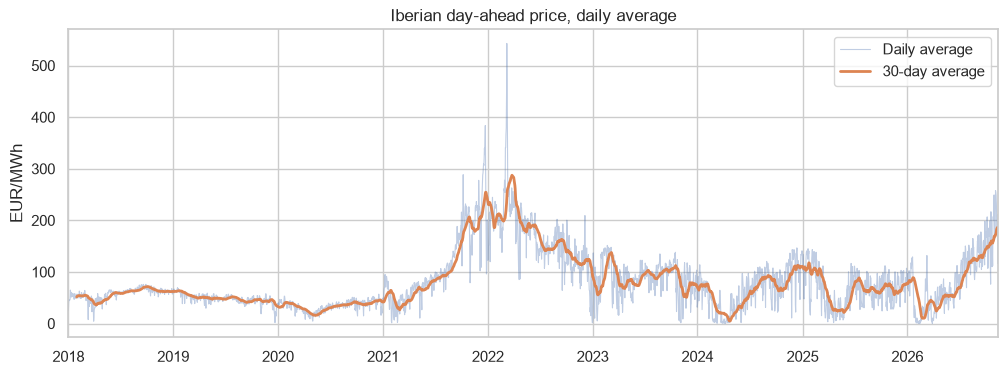

In [5]:
daily = df[PRICE].resample("D").mean()

ax = daily.plot(alpha=0.35, lw=0.8, label="Daily average")
daily.rolling(30).mean().plot(ax=ax, lw=2, label="30-day average")
ax.set(title="Iberian day-ahead price, daily average", ylabel="EUR/MWh", xlabel="")
ax.legend()
ax.figure.savefig(FIGURES / "price_history.png", dpi=150, bbox_inches="tight");

In [6]:
# Yearly averages, PT and ES
df.groupby("year")[["price_pt", "price_es"]].mean()

,price_pt,price_es
year,,
2018,57.45,57.29
2019,47.87,47.68
2020,33.99,33.96
2021,112.01,111.93
2022,167.89,167.52
2023,88.27,87.10
2024,63.45,63.04
2025,66.19,65.29
2026,88.73,88.43


## 2 · Distribution and volatility by year

The box shows the middle 50 % of hourly prices in each year; the line inside is the median.
The second chart shows the average **daily range** (highest minus lowest hour of the day),
which is what a battery could earn from in theory.

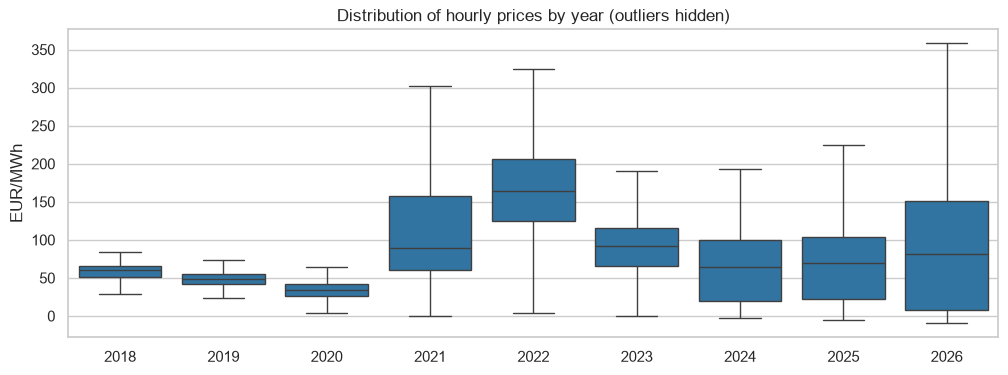

In [7]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="year", y=PRICE, showfliers=False, color="tab:blue", ax=ax)
ax.set(title="Distribution of hourly prices by year (outliers hidden)", ylabel="EUR/MWh", xlabel="");

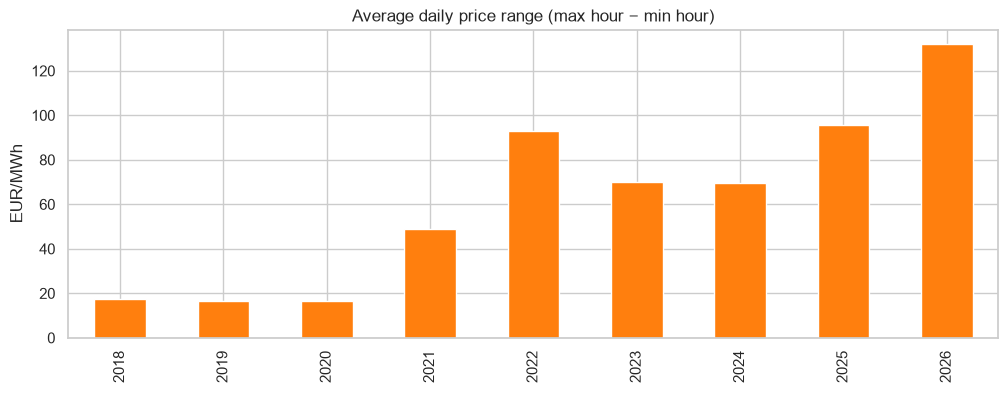

In [8]:
daily_max = df[PRICE].resample("D").max()
daily_min = df[PRICE].resample("D").min()
daily_range = (daily_max - daily_min).rename("daily_range")

ax = daily_range.groupby(daily_range.index.year).mean().plot.bar(color="tab:orange")
ax.set(title="Average daily price range (max hour − min hour)", ylabel="EUR/MWh", xlabel="");

## 3 · Daily profile: how the shape of the day changed

Average price for each hour of the day, one line per year.

The second chart removes each day's average first (price **relative to the daily mean**),
so years with very different price levels can be compared by **shape** only.
Look for: a midday dip that deepens over the years as solar capacity grows (the "duck curve"),
and where the daily peak sits.

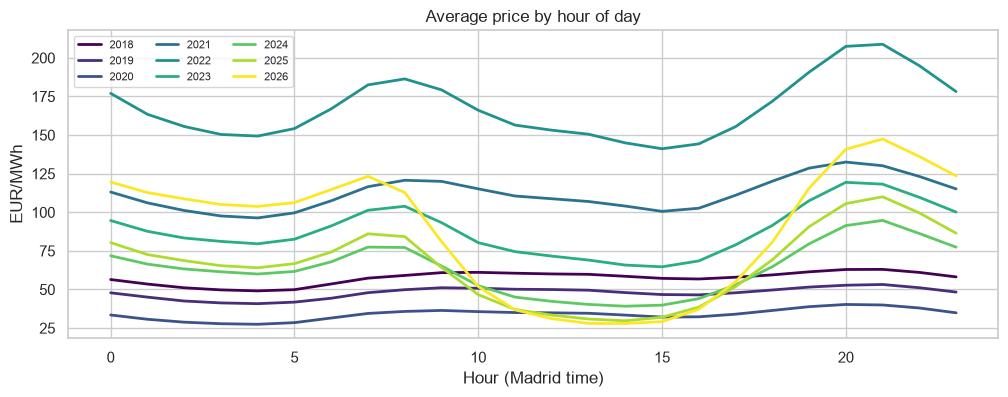

In [9]:
profile = df.pivot_table(index="hour", columns="year", values=PRICE, aggfunc="mean")
ax = profile.plot(colormap="viridis", lw=2)
ax.set(title="Average price by hour of day", xlabel="Hour (Madrid time)", ylabel="EUR/MWh")
ax.legend(ncol=3, fontsize=8);

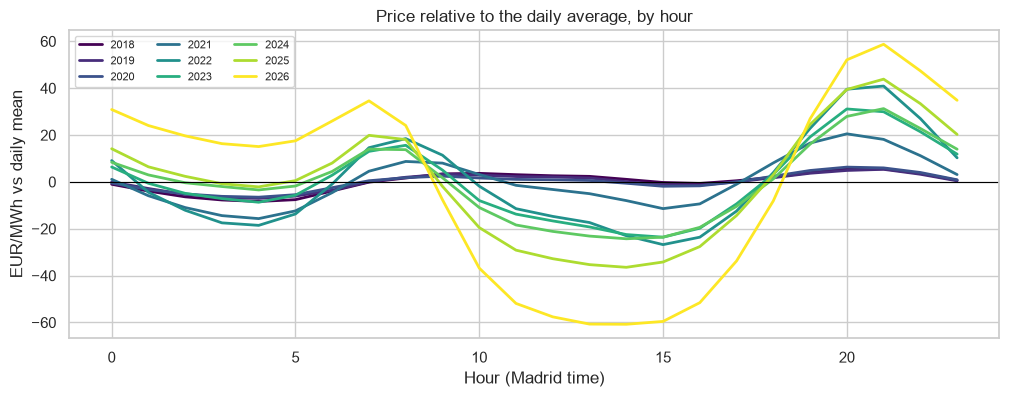

In [10]:
relative = df[PRICE] - df.groupby("date")[PRICE].transform("mean")
rel_profile = relative.groupby([df["hour"], df["year"]]).mean().unstack()

ax = rel_profile.plot(colormap="viridis", lw=2)
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Price relative to the daily average, by hour", xlabel="Hour (Madrid time)",
       ylabel="EUR/MWh vs daily mean")
ax.legend(ncol=3, fontsize=8)
ax.figure.savefig(FIGURES / "daily_profile_relative.png", dpi=150, bbox_inches="tight");

## 4 · When in the year and the day are prices high? (hour × month heatmap)

Each cell is the average price for that hour of the day in that month.

✏️ Try: change `YEAR` to compare, e.g. 2019 (before the crisis) with 2025.

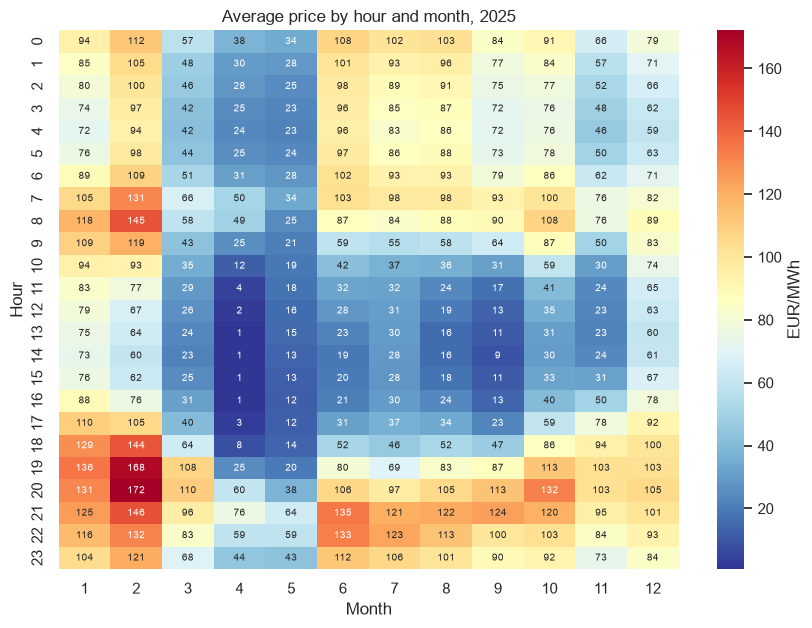

In [11]:
YEAR = 2025

heat = df[df["year"] == YEAR].pivot_table(index="hour", columns="month", values=PRICE,
                                          aggfunc="mean")
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(heat, cmap="RdYlBu_r", annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "EUR/MWh"}, ax=ax)
ax.set(title=f"Average price by hour and month, {YEAR}", xlabel="Month", ylabel="Hour")
fig.savefig(FIGURES / "heatmap_hour_month.png", dpi=150, bbox_inches="tight");

## 5 · Weekdays vs weekends

Demand is lower at weekends, so prices should be too. How big is the effect, and at which hours?
Uses recent years only (2023 onwards) so the crisis does not dominate the averages.

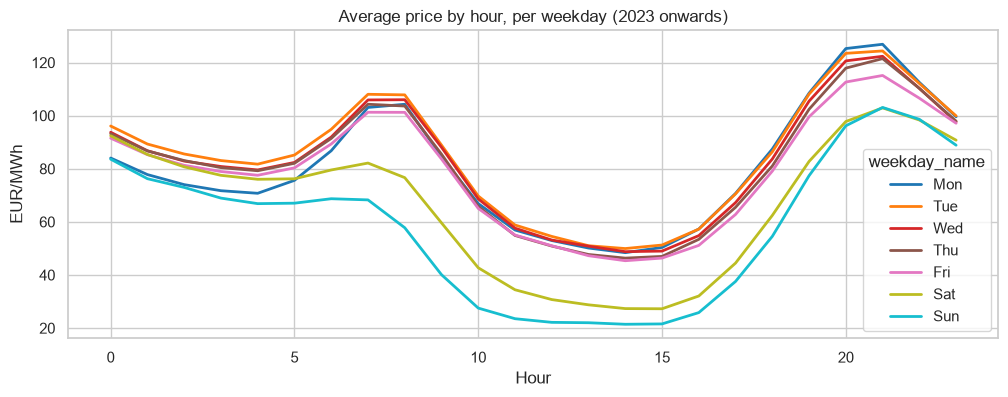

In [12]:
recent = df[df["year"] >= 2023]

week_profile = recent.pivot_table(index="hour", columns="weekday_name", values=PRICE,
                                  aggfunc="mean", observed=True)
ax = week_profile.plot(colormap="tab10", lw=2)
ax.set(title="Average price by hour, per weekday (2023 onwards)", xlabel="Hour", ylabel="EUR/MWh");

In [13]:
recent.groupby("is_weekend")[PRICE].mean().rename({False: "weekday", True: "weekend"})

is_weekend
weekday    81.92
weekend    62.08
Name: price_pt, dtype: float64

## 6 · Extremes: negative prices and spikes

Negative prices mean producers pay to keep generating, typically on sunny, windy spring days
with low demand. Spikes are the opposite: tight supply, expensive gas, low wind.

Hours with negative prices: 1,009 (first: 2024-04-05)


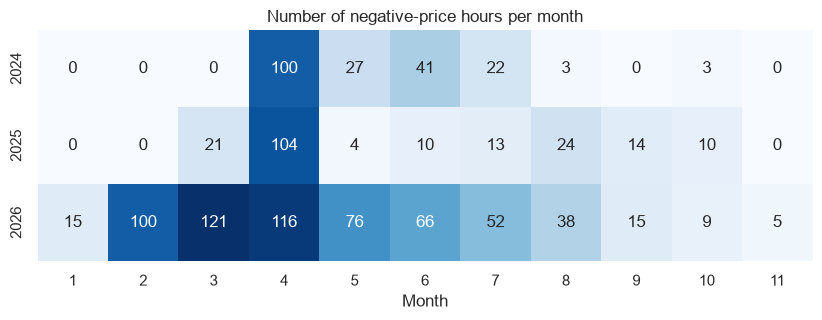

In [14]:
negative = df[df[PRICE] < 0]
print(f"Hours with negative prices: {len(negative):,} (first: {negative.index.min():%Y-%m-%d})")

neg_by_month = negative.groupby(["year", "month"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(10, 3))
sns.heatmap(neg_by_month, cmap="Blues", annot=True, fmt="d", cbar=False, ax=ax)
ax.set(title="Number of negative-price hours per month", xlabel="Month", ylabel="")
fig.savefig(FIGURES / "negative_prices.png", dpi=150, bbox_inches="tight");

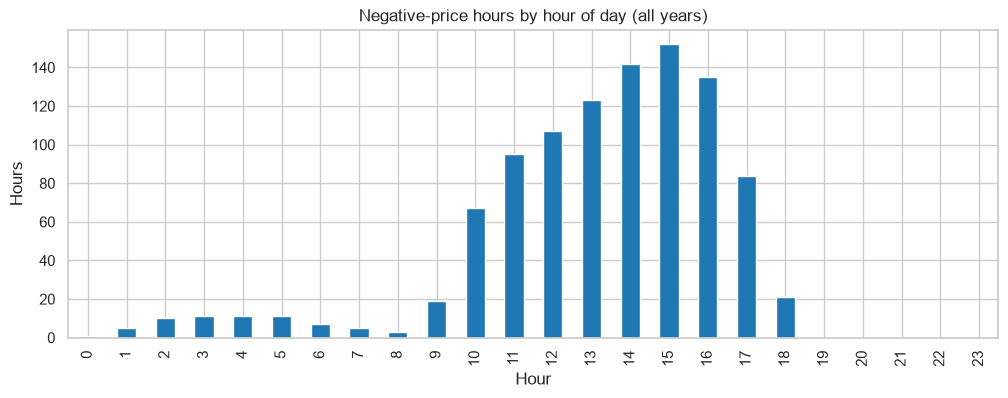

In [15]:
ax = negative.groupby("hour").size().reindex(range(24), fill_value=0).plot.bar(color="tab:blue")
ax.set(title="Negative-price hours by hour of day (all years)", xlabel="Hour", ylabel="Hours");

In [16]:
# The 10 most expensive days (daily average) and the 10 most expensive single hours
print("Top 10 days by average price:")
display(daily.nlargest(10).round(1).to_frame("daily_avg"))
print("Top 10 hours:")
display(df[PRICE].nlargest(10).to_frame())

Top 10 days by average price:


,daily_avg
datetime_local,
2022-03-08 00:00:00+01:00,542.8
2022-03-09 00:00:00+01:00,473.0
2022-03-07 00:00:00+01:00,442.5
2021-12-23 00:00:00+01:00,383.7
2022-03-06 00:00:00+01:00,379.0
2022-03-10 00:00:00+01:00,369.7
2022-03-05 00:00:00+01:00,366.5
2021-12-22 00:00:00+01:00,360.0
2022-03-03 00:00:00+01:00,341.1


Top 10 hours:


,price_pt
datetime_local,
2022-03-08 18:00:00+01:00,651.00
2022-03-08 19:00:00+01:00,651.00
2022-03-08 20:00:00+01:00,651.00
2022-03-08 21:00:00+01:00,651.00
2022-03-08 22:00:00+01:00,650.00
2022-03-08 08:00:00+01:00,645.00
2022-03-09 19:00:00+01:00,605.00
2022-03-08 17:00:00+01:00,603.08
2022-03-08 09:00:00+01:00,601.00


## 7 · Portugal vs Spain

The two countries share one market and usually have the same price. They split when the
interconnection between them is full ("market splitting").

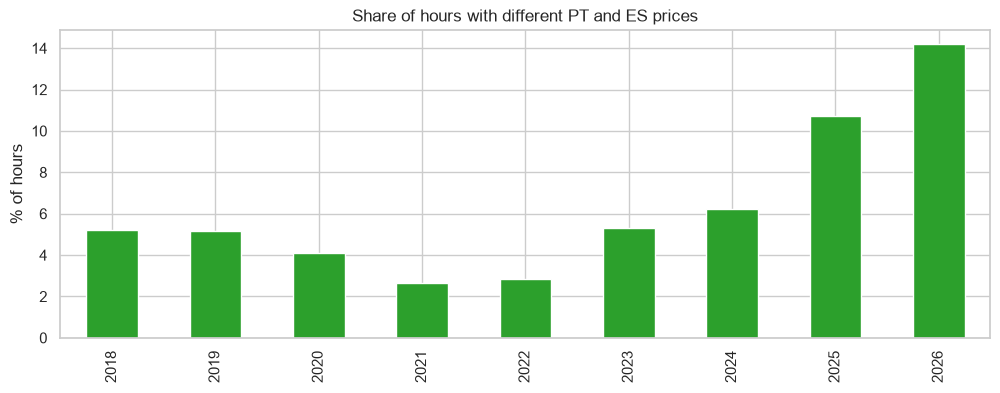

In [17]:
diff = df["price_pt"] - df["price_es"]
split = diff.abs() > 0.005

ax = split.groupby(df["year"]).mean().mul(100).plot.bar(color="tab:green")
ax.set(title="Share of hours with different PT and ES prices", ylabel="% of hours", xlabel="")
ax.figure.savefig(FIGURES / "pt_es_split.png", dpi=150, bbox_inches="tight");

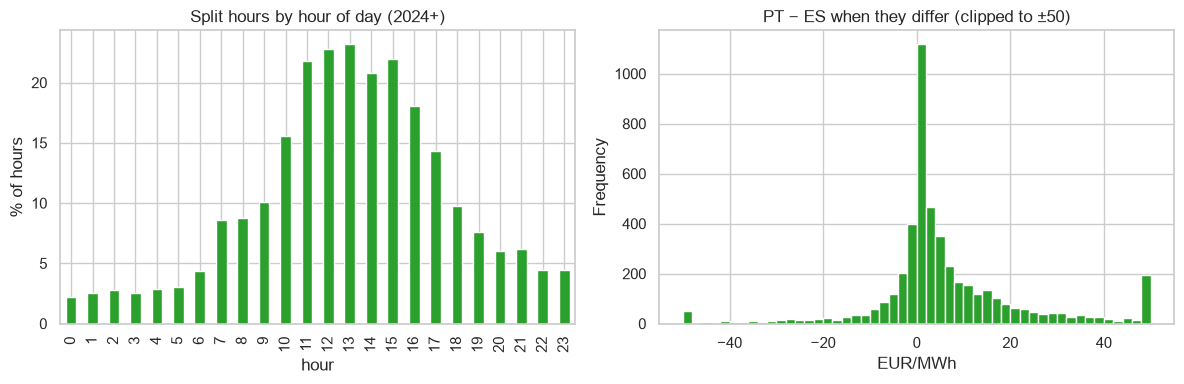

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
split[df["year"] >= 2024].groupby(df["hour"]).mean().mul(100).plot.bar(
    ax=axes[0], color="tab:green", title="Split hours by hour of day (2024+)", ylabel="% of hours")
diff[split].clip(-50, 50).plot.hist(bins=50, ax=axes[1], color="tab:green",
                                    title="PT − ES when they differ (clipped to ±50)")
axes[1].set_xlabel("EUR/MWh")
plt.tight_layout()

## 8 · How predictable is the price? (autocorrelation)

Autocorrelation measures how similar the price is to itself *n* hours earlier.
Strong peaks at 24 h (same hour yesterday) and 168 h (same hour last week) are why the
**naive forecasts** in step 4 are "same hour yesterday" and "same hour last week".

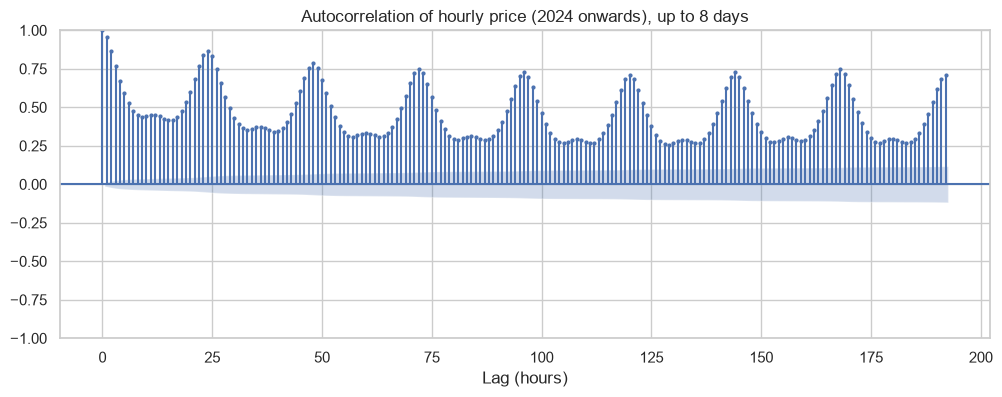

In [19]:
fig, ax = plt.subplots()
plot_acf(df.loc["2024":, PRICE], lags=24 * 8, ax=ax, markersize=2)
ax.set(title="Autocorrelation of hourly price (2024 onwards), up to 8 days", xlabel="Lag (hours)");

In [20]:
# Preview of step 4: how wrong would the naive forecasts have been?
# MAE = mean absolute error, in EUR/MWh
s = df[PRICE]
naive = pd.DataFrame({
    "same hour yesterday": (s - s.shift(24)).abs(),
    "same hour last week": (s - s.shift(168)).abs(),
})
naive.groupby(df["year"]).mean().round(1)

,same hour yesterday,same hour last week
year,,
2018,5.2,6.4
2019,5.1,6.7
2020,5.3,6.7
2021,15.9,24.9
2022,27.2,39.6
2023,19.6,28.7
2024,18.1,27.0
2025,19.9,29.3
2026,21.2,30.3


## 9 · Key takeaways

✏️ Write your own observations here after exploring: 4–6 short bullets. These will feed the
README and decide which features the models in step 4 use.

- There is an increase in the share of hours that have different prices between Portugal and Spain
- Prices vary more in more recent years (does it have to do with an increase of sampling frequency?)
- There is a high correlation in the energy price within a 24h period, which is no surprise since the planet completes one revolution (1 cycle).
- In 2021, 2022 and 2026 there is a wider span of prices per hour (is it related to any noise?)